# Test Technique Data Science Ismael FOUDJO

Projet 2 : construire un modèle permettant de prédire les données de température humide à partir des données atmosphériques.

Temps passé : environ 6h 

1. Importation des librairies utiles

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Math

2. Chargement du jeu de données "dtf_test_nettoyée"

In [3]:
dtf1=pd.read_csv("C:/Users/ismae/Desktop/Projets data Science/Dataset/dtf_test_nettoyée.csv")
dtf1.head(5)


,Unnamed: 0,date,hour,station_id,nbre_records,T2M,DEWT2M,RH2M,WS2M,WS10M,WD,VPD,CLDC,SSI,PRECIP,lat,lon,T2M_D_med,T2M_U_med
0,0,2020-03-15,1,1176,5,4.1,4.1,100.0,0.45,0.6,132.0,0.00,59.0,0.0,0.0,44.70687,-0.61908,0.3,0.1
1,1,2020-03-15,1,2030,6,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,47.27178,-1.65603,9.8,7.8
2,7,2020-03-15,1,3324,4,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,47.27163,-1.65622,10.4,10.7
3,8,2020-03-15,1,3898,5,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,47.27177,-1.65600,9.4,7.5
4,9,2020-03-15,1,3899,6,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,47.27172,-1.65615,9.5,7.7


3.  Sélection des données du 15/03/2020 au 14/03/2023.

In [4]:
# Convertir en format datetime, on peut avoir certains formats en chaine de caractères. 
dtf1['date']=pd.to_datetime(dtf1['date'])

In [5]:
dtf1 = dtf1[(dtf1['date'] >= '15-03-2020') & (dtf1['date']<= '14-03-2023')]

In [6]:
dtf1.describe()

,Unnamed: 0,date,hour,station_id,nbre_records,T2M,DEWT2M,RH2M,WS2M,WS10M,WD,VPD,CLDC,SSI,PRECIP,lat,lon,T2M_D_med,T2M_U_med
count,1.486359e+06,1486359,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06,1.486359e+06
mean,4.869002e+06,2022-04-02 14:27:41.563054336,1.145862e+01,9.617286e+03,5.270694e+00,4.917841e+00,2.320424e+00,8.461599e+01,2.107611e+00,2.817954e+00,1.795992e+02,1.387757e-01,6.001780e+01,1.096309e+00,7.004674e-02,4.563295e+01,2.448904e+00,4.045836e+00,3.598644e+00
min,0.000000e+00,2020-03-15 00:00:00,1.000000e+00,1.176000e+03,4.000000e+00,-1.190000e+01,-4.600000e+01,2.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.113933e+01,-4.427380e+00,-1.455000e+01,-1.510000e+01
25%,2.792396e+06,2021-11-20 00:00:00,4.000000e+00,6.579000e+03,5.000000e+00,2.200000e+00,-7.000000e-01,7.700000e+01,8.200000e-01,1.100000e+00,9.100000e+01,4.000000e-02,0.000000e+00,0.000000e+00,0.000000e+00,4.412180e+01,-1.689500e-01,1.400000e+00,9.000000e-01
50%,3.873346e+06,2022-04-03 00:00:00,7.000000e+00,8.805000e+03,5.000000e+00,5.400000e+00,2.500000e+00,8.800000e+01,1.650000e+00,2.200000e+00,1.770000e+02,1.000000e-01,9.800000e+01,0.000000e+00,0.000000e+00,4.501744e+01,2.166100e+00,4.500000e+00,4.000000e+00
75%,8.057022e+06,2023-01-04 00:00:00,2.000000e+01,1.370000e+04,6.000000e+00,8.000000e+00,5.700000e+00,9.500000e+01,2.920000e+00,3.900000e+00,2.630000e+02,2.000000e-01,1.000000e+02,0.000000e+00,0.000000e+00,4.714145e+01,4.798220e+00,7.100000e+00,6.600000e+00
max,9.062749e+06,2023-03-14 00:00:00,2.400000e+01,2.228500e+04,1.200000e+01,1.000000e+01,1.000000e+01,1.000000e+02,2.199000e+01,2.940000e+01,3.600000e+02,1.030000e+00,1.000000e+02,5.000000e+01,2.370000e+01,5.100133e+01,9.853420e+00,1.150000e+01,1.200000e+01
std,2.979296e+06,NaN,8.409758e+00,3.561339e+03,9.098323e-01,3.562892e+00,4.113729e+00,1.333896e+01,1.832261e+00,2.449541e+00,1.018554e+02,1.311849e-01,4.613616e+01,5.991644e+00,3.677453e-01,1.670954e+00,2.510987e+00,3.762634e+00,3.716283e+00


4. Sélection des variables pertinentes pour la prédiction 

In [7]:
dtf1=dtf1[['T2M', 'DEWT2M', 'RH2M', 'WS2M', 'WS10M', 'WD', 'VPD', 'CLDC', 'SSI','PRECIP', 'T2M_D_med']]
dtf1.head(5)

,T2M,DEWT2M,RH2M,WS2M,WS10M,WD,VPD,CLDC,SSI,PRECIP,T2M_D_med
0,4.1,4.1,100.0,0.45,0.6,132.0,0.00,59.0,0.0,0.0,0.3
1,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,9.8
2,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,10.4
3,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,9.4
4,9.8,4.5,70.0,3.29,4.4,198.0,0.36,27.0,0.0,0.0,9.5


# 1. Modèle de machine learning :  forêts aléatoire pour prédire  T2M_U_med à partir des données

4. Séparer les données en deux sous-bases : entraînement et test.

In [8]:
x= dtf1.drop('T2M_D_med', axis=1)
y=dtf1.T2M_D_med.values

In [9]:
#sns.pairplot(dtf1);

In [10]:
# Separer les données en deux sous bases: entrainnement et test ( 70 % pour l'entrainement et 30 % pour le test)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train,y_test = train_test_split(x,y, test_size=0.3, random_state=42)

5. Utiliser le modèle Random Forest pour entrainer les données 

In [11]:
# Problème de regression
from sklearn.ensemble import RandomForestRegressor
model_Reg= RandomForestRegressor(n_estimators=50, random_state=102)

In [12]:
# Entrainement du modèle 
model_Reg.fit(X_train, y_train)

RandomForestRegressor(n_estimators=50, random_state=102)

6. Prédictipn du modèle 

In [13]:
y_pred=model_Reg.predict(X_test)

7. Mesure des performances du modèle avec le mean square error

In [14]:
from sklearn.metrics import mean_squared_error
MSE= mean_squared_error(y_test,y_pred)

print("L'Erreur Moyenne Quadratique est : {}".format(MSE))


L'Erreur Moyenne Quadratique est : 1.2968289508364637


In [15]:
np.sqrt(MSE)

1.1387839790041234

Conclusion : 

En utilisant le modèle de ML Forest aléatoire et la métrique de performances MSE, nous trouvons en moyenne une erreur de prédiction de 1.13°C sur la température humide.

8. Mesure des performances du modèle avec le R2

In [16]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test,y_pred)
print("coéfficient de determination est : {}".format(r2))

coéfficient de determination est : 0.9083671451847086


Conclusion : 

En utilisant le modèle de ML Forest aléatoire et le coefficient de détermination R carré, nous trouvons R2 qui indique un modèle qui ajuste bien les données, suggérant une bonne capacité à prédire la variable cible avec une erreur de près de 9.17 %.

Dispersion des erreurs en fonction de la valeur prédite

Text(0.5, 1.0, ' Graphique des residus vs valeurs prédite pour le modèle de machine learning')

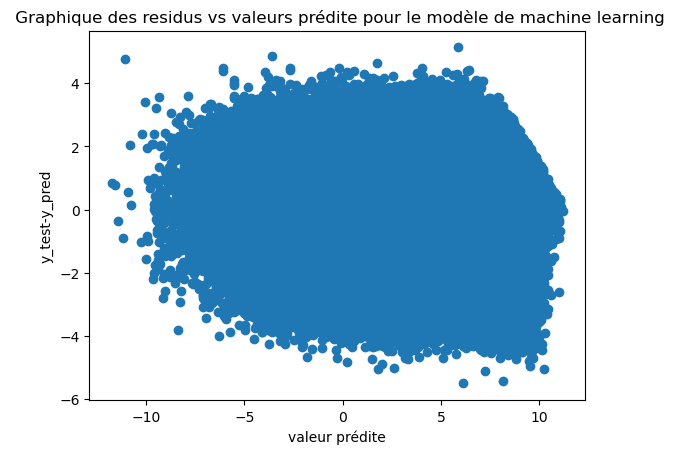

In [17]:
plt.scatter(y_pred,y_test-y_pred)
plt.xlabel("valeur prédite")
plt.ylabel("y_test-y_pred")
plt.title(" Graphique des residus vs valeurs prédite pour le modèle de machine learning")

Nous pouvons remarquer que sur ce graphique, nous avons un motif aléatoire (les résidus apparaissent autour de zéro sans structure évidente). Nous pouvons donc suggérer que le modèle est approprié. 

# 2. Régression polynomiale

In [18]:
x= dtf1.drop('T2M_D_med', axis=1)
y=dtf1.T2M_D_med.values

1. Importation des bibliothèques utiles

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures 

2. Entrainement du modèle

In [20]:
polynomial_features= PolynomialFeatures(degree=3)
x_poly = polynomial_features.fit_transform(x)
model = LinearRegression()
model.fit(x_poly, y)
 

LinearRegression()

3. Prediction 

In [21]:
y_poly_pred = model.predict(x_poly)

4. Mesure des performances du modèle avec le mean square error (MSE)

In [22]:
MSE= np.sqrt(mean_squared_error(y,y_poly_pred))

print(" La racine carrée de l'Erreur Moyenne Quadratique est : {}".format(MSE))


 La racine carrée de l'Erreur Moyenne Quadratique est : 1.1733290848042552


Conclusion : 

En utilisant la régression polynomiale et la métrique de performances MSE, nous trouvons en moyenne une erreur de prédiction de 1.17°C sur la température humide.

5. Mesure des performances du modèle avec le coefficient de détermination

In [23]:
from sklearn.metrics import r2_score
r2 = r2_score(y,y_poly_pred)
print("coéfficient de determination est : {}".format(r2))


coéfficient de determination est : 0.9027575157183074


Conclusion :

En utilisant la régression polynomiale et le coefficient de détermination R carré, nous trouvons R2=0.9027 qui indique un modèle qui ajuste bien les données, suggérant une bonne capacité à prédire la variable cible avec une erreur de près de 9.73 %.

Dispersion des erreurs en fonction de la valeur prédite

Text(0.5, 1.0, ' Graphique des residus vs valeurs prédite pour la regression polynomiale')

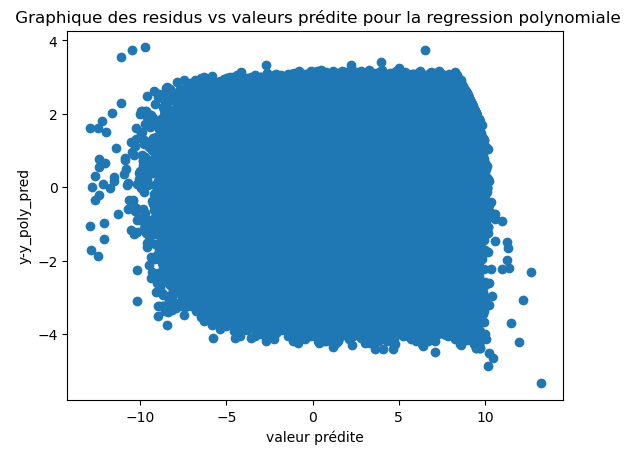

In [39]:
plt.scatter(y_poly_pred,y-y_poly_pred)
plt.xlabel("valeur prédite")
plt.ylabel("y-y_poly_pred")
plt.title(" Graphique des residus vs valeurs prédite pour la regression polynomiale")

Nous pouvons remarquer que sur ce graphique, nous avons un motif aléatoire (les résidus apparaissent autour de zéro sans structure évidente). Nous pouvons donc suggérer que le modèle est approprié. 

# 3. Formule de Stull simplifiée pour la prediction de la Temperature humide

1. Importations des bibliothèques nécessaires

In [27]:
from scipy.optimize import curve_fit

2. Définition  des données

In [28]:
Ts= dtf1['T2M']
hr=dtf1['RH2M']
#Tw=y
Tw=0.2831*hr**(0.2735)*Ts + 0.0003018*hr**2 + 0.01289*hr-4.0962
hr=dtf1['RH2M']

3. Définition de la fonction modele

In [29]:
def modele ( hr1, a,b,c,d):
    return a*hr1**(0.2735)*Ts + b**hr1**2 + c*hr1-d

5. Ajuster le modèle avec curve_fit

In [30]:
popt,pcov=curve_fit(modele, hr,Tw)
# popt contient les valeurs optimisées des paramètre (a,b,c et d)

6. prédictions

In [31]:
Tw_pred=modele(hr,*popt)

7. Mesure des performances

In [32]:
MSE= np.sqrt(mean_squared_error(Tw,Tw_pred))

print(" La racine carrée de l'Erreur Moyenne Quadratique est : {}".format(MSE))


 La racine carrée de l'Erreur Moyenne Quadratique est : 0.01089345119161121


Conclusion : 

En utilisant la formule de Stull simplifiée et la métrique de performances MSE, nous trouvons en moyenne une erreur de prédiction de 0.01°C sur la température humide.

In [33]:
r2 = r2_score(Tw,Tw_pred)
print("coéfficient de determination est : {}".format(r2))

coéfficient de determination est : 0.9999901881203032


Conclusion : 

En utilisant la formule de Stull simplifiée   et le coefficient de détermination R carré, nous trouvons R2=0.9999901 qui indique un modèle qui ajuste bien les données, suggérant une bonne capacité à prédire (toutes les prédictions sont presque exactes).

Dispersion des erreurs en fonction de la valeur prédite

Text(0.5, 1.0, ' Graphique des residus vs valeurs prédite pour la formule de Stull')

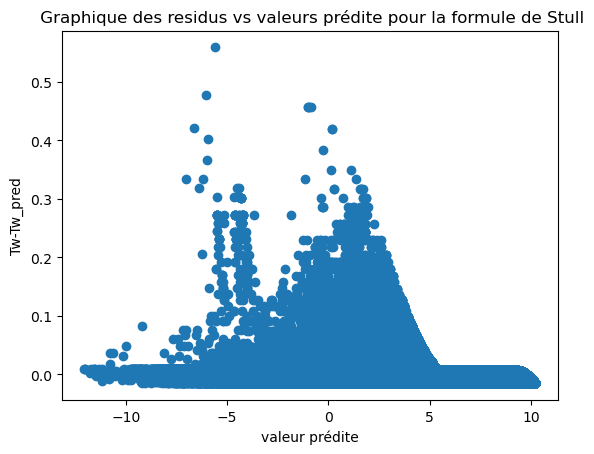

In [40]:
# Courbe de MSE 
plt.scatter(Tw_pred,Tw-Tw_pred)
plt.xlabel("valeur prédite")
plt.ylabel("Tw-Tw_pred")
plt.title(" Graphique des residus vs valeurs prédite pour la formule de Stull")

Nous pouvons remarquer que sur ce graphique, nous avons un motif aléatoire (les résidus apparaissent autour de zéro sans structure évidente). Nous pouvons donc suggérer que le modèle est approprié. 

8. Visualisation

c:\Users\ismae\anaconda3\Lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
c:\Users\ismae\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


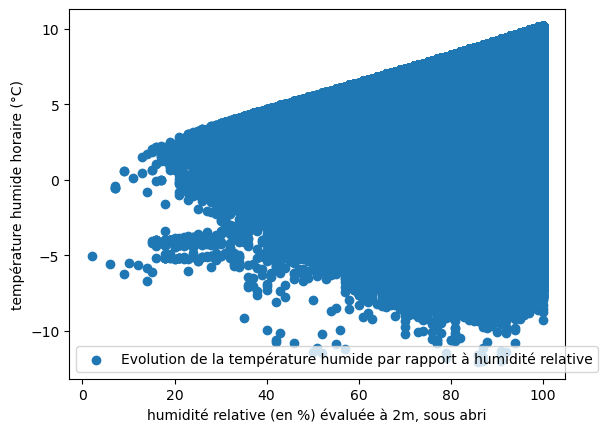

In [37]:
plt.scatter(hr,Tw, label='Evolution de la température humide par rapport à humidité relative');
plt.xlabel('humidité relative (en %) évaluée à 2m, sous abri')
plt.ylabel('température humide horaire (°C)')
plt.legend()

Text(0, 0.5, 'température humide horaire prédite (°C)')

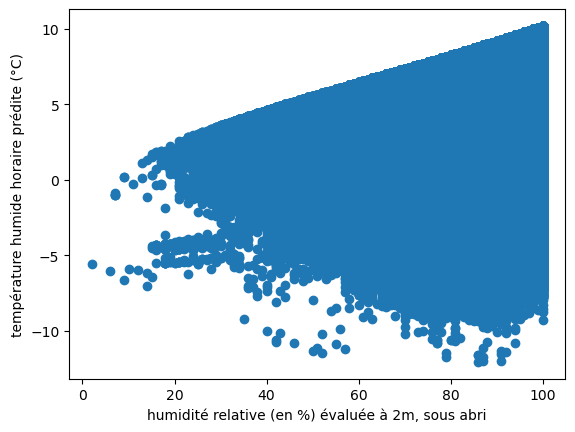

In [157]:
plt.scatter(hr,Tw_pred)
plt.xlabel('humidité relative (en %) évaluée à 2m, sous abri')
plt.ylabel('température humide horaire prédite (°C)')

# 4. Comparaison des 3 approches proposées pour prédire la température humide

# Introduction

L'objectif de cette deuxième partie du test de Data Science vise à prédire au mieux la temperature humide T2M_U_med en fonction de plusieurs variables pertinentes sectionnées, en utilisant 3 approches de modélisation des données telles que : le modèle de machine learning (forêts aléatoires), la régression polynomiale et la formule de Stull simplifiée. Les données proviennent chez Weenat qui déploie des stations pour le suivi du gel mesurant les valeurs de température sèche et de température humide à hauteur de végétal (env. 50cm) sans abri pour la période du 15/03/2020 au 14/03/2023.


# Description des données 

 Colonnes de la base de données :
- T2M : température (en °C) évaluée à 2m sous abri ;
- DEWT2M :  température au point de rosée (en °C) évaluée à 2m, sous abri ;
- RH2M : humidité relative (en %) évaluée à 2m, sous abri;
- WS2M : vitesse du vent (en m/s) évaluée à 2m, en terrain dégagé ;
- WS10M : vitesse du vent (en m/s) évaluée à 10m, en terrain dégagé ;
- WD : direction du vent (en °, initialisée par un vent venant du Nord pour 0°, évaluée dans le sens anti-trigonométrique) évaluée à 10m, en terrain dégagé ;
- VPD : déficit de pression saturante (en kPa) ;
- CLDC : couverture nuageuse (en %) ;
- SSI : rayonnement solaire (en W/m²) mesuré au sol, sous l’hypothèse d’un plan horizontal sous un rayonnement zénithal ;
- PRECIP : quantité de précipitation (en mm) évaluée à 2m, en terrain dégagé.
- T2M_U_med : température humide horaire sans abri, évaluée à 50cm (valeur médiane des mesures de l’heure précédente).

 Les données venant de Weenat présentent des principales variables (features) suivantes : T2M, DEWT2M, RH2M, WS2M, WS10M, WD, VPD, CLDC, SSI et PRECIP et de variables cible( target): T2M_U_med.

 Un prétraitement effectué au projet 1 nous a permis de nettoyer les données, de gérer les valeurs manquantes et de transformer certaines variables (au départ, nous avons une base de données de 11.773.387 mesures et après prétraitement, il reste 1.753.569).



# Médhodologie

   Nous allons utiliser les trois modèles suivants pour prédire la valeur de la température humide et ensuite faire une comparaison à travers les métriques d'évaluation des performances ( MSE et R carré).

   - Le modèle de machine learning (forêts aléatoires)
   - La régression polynomiale
   - La formule de Stull simplifiée

   Formules mathématiques des métriques de performance utilisées :

In [178]:

display(Math(r"MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2"))

<IPython.core.display.Math object>

In [180]:
display(Math(r'R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}'))

<IPython.core.display.Math object>

# Modélisation 

Modèle de machine learning (forêts aléatoire): 

Ce modèle ensembliste combine plusieurs arbres de décision, dont chacun étant construit sur un sous-ensemble aléatoire des données. La prédiction finale, dans ce cas, se fait par la moyenne des prédictions.

Résultats des performances sur les données test : 

MSE= 1.2968289508364637

R^2= 0.9083671451847086

Conclusion :

- En utilisant le modèle de ML forêts  aléatoire et la métrique de performances MSE, nous trouvons en moyenne une erreur de prédiction de 1.13°C sur la température humide.

- En utilisant le modèle de ML forêts aléatoire et le coefficient de détermination R carré, nous trouvons R2 qui indique un modèle qui ajuste bien les données, suggérant une bonne capacité à prédire la variable cible avec une erreur de près de 9.17 %.


La régression polynomiale

Cette forme de modélisation, qui est une extension de la régression linéaire  permet de capturer les relations entre les données en ajustant la courbe aux données. Dans ce cas, nous avons décidé de travailler avec un polynôme de degré 3. 

y= b0 + b1*x + b2*x^2 + ........... +  bn*x^n


MSE= 1.3767011412475911

R^2= 0.902757515718307

Conclusion :

- En utilisant la régression polynomiale et la métrique de performances MSE, nous trouvons en moyenne une erreur de prédiction de 1.17°C sur la température humide.

- En utilisant la régression polynomiale et le coefficient de détermination R carré, nous trouvons R2=0.9027 qui indique un modèle qui ajuste bien les données, suggérant une bonne capacité à prédire la variable cible avec une erreur de près de 9.73 %.




Formule de Stull simplifiée pour la prediction de la Temperature humide

Nous allons utiliser curve_fit pour ajuster les meilleurs paramètres (a,b,c,d) de la formule de Stull pour que le modèle puisse mieux apprendre des données.

Formule de Stull utilisée Tw= a * hr^(0.2735) * Ts + b * hr^2 + c * hr-d

MSE= 0.00011866727886401568

R^2= 0.9999901881203032

Conclusion :

- En utilisant la formule de Stull simplifiée et la métrique de performances MSE, nous trouvons en moyenne une erreur de prédiction de 0.01°C sur la température humide.


- En utilisant la formule de Stull simplifiée   et le coefficient de détermination R carré, nous trouvons R2=0.9999901 qui indique un modèle qui ajuste bien les données, suggérant une bonne capacité à prédire ( toutes les prédictions sont presque exactes).







# Comparaison des trois approches

L'approche qui prédit au mieux la température humide est celle dont son Erreur Moyenne Quadratique sera la plus minimale possible et le coefficient de détermination proche de 1. 

Compte tenu des résultats précédents des valeurs de MSE et R2 pour les 3 approches, nous pouvons conclure que l'approche la plus efficace pour prédire la température humide est l'utilisation de la formule de Stull  ( MSE= 0.00011866727886401568, R^2= 0.9999901881203032 ), ensuite le modèle de forêts aléatoire (MSE= 1.2968289508364637, R^2= 0.9083671451847086) et pour terminer, La régression polynomiale ( MSE= 1.3767011412475911, R^2= 0.902757515718307).
